#Recommended EDA practice structure

You can practice in this order:

1. Load the dataset
2. shape, head(), tail()
3. info()
4. Check missing values
5. Check duplicates
6. Statistical summary
7. Unique values
8. Categorical distributions
9. Numerical distributions
10. Outlier detection
11. Date/time analysis
12. Correlation analysis
13. Fraud vs non-fraud analysis
14. Feature relationships
15. Draw conclusions

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import seaborn as sns

#Dataset Understanding
Q1. Load the CSV into a DataFrame named df.<br>
Q2. Find the number of rows and columns, and display the first and last five rows.<br>
Q3. Display all column names and their data types. Classify columns as numerical, categorical, or
identifier-like.<br>
Q4. Use info() and identify columns that may need special attention.<br>

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/HR_Employee_Attrition_EDA_Practice.csv')

In [ ]:
print(df.shape)
print(df.columns.values)
print(df.isnull().sum()[df.isnull().sum() > 0])

(1505, 35)
['Age' 'Attrition' 'BusinessTravel' 'DailyRate' 'Department'
 'DistanceFromHome' 'Education' 'EducationField' 'EmployeeCount'
 'EmployeeNumber' 'EnvironmentSatisfaction' 'Gender' 'HourlyRate'
 'JobInvolvement' 'JobLevel' 'JobRole' 'JobSatisfaction' 'MaritalStatus'
 'MonthlyIncome' 'MonthlyRate' 'NumCompaniesWorked' 'Over18' 'OverTime'
 'PercentSalaryHike' 'PerformanceRating' 'RelationshipSatisfaction'
 'StandardHours' 'StockOptionLevel' 'TotalWorkingYears'
 'TrainingTimesLastYear' 'WorkLifeBalance' 'YearsAtCompany'
 'YearsInCurrentRole' 'YearsSinceLastPromotion' 'YearsWithCurrManager']
BusinessTravel              4
DistanceFromHome           15
EnvironmentSatisfaction    10
JobRole                    18
MaritalStatus               8
MonthlyIncome              26
OverTime                   12
dtype: int64


In [ ]:
df.head(5)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,28,Yes,Travel_Rarely,1434.0,Research & Development,5.0,4,Technical Degree,1,65,...,3,80,0,2,3,2,2,2,2,2
1,56,No,Travel_Rarely,1369.0,Research & Development,23.0,3,Life Sciences,1,1373,...,1,80,1,33,0,3,19,16,15,9
2,53,No,Travel_Rarely,1084.0,Research & Development,13.0,2,Medical,1,250,...,3,80,2,5,3,3,4,2,1,3
3,37,No,Travel_Rarely,1462.0,Research & Development,11.0,3,Medical,1,1411,...,1,80,0,8,6,3,3,2,0,2
4,41,No,Non-Travel,247.0,Research & Development,7.0,1,Life Sciences,1,1035,...,2,80,2,21,3,3,21,16,5,10


In [ ]:
df.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1500,35,No,Travel_Rarely,750.0,Research & Development,28.0,3,Life Sciences,1,1596,...,4,80,2,10,3,2,10,9,6,8
1501,41,No,Travel_Rarely,447.0,Research & Development,5.0,3,Life Sciences,1,1814,...,1,80,0,11,3,1,3,2,1,2
1502,22,Yes,Travel_Frequently,1256.0,Research & Development,3.0,4,Life Sciences,1,1203,...,2,80,1,1,5,3,0,0,0,0
1503,29,No,Travel_Rarely,1378.0,Research & Development,13.0,2,Other,1,2053,...,1,80,1,10,2,3,4,3,0,3
1504,50,No,Travel_Rarely,264.0,Sales,9.0,3,Marketing,1,1591,...,3,80,1,27,2,3,1,0,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1505 entries, 0 to 1504
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1505 non-null   int64  
 1   Attrition                 1505 non-null   object 
 2   BusinessTravel            1501 non-null   object 
 3   DailyRate                 1505 non-null   float64
 4   Department                1505 non-null   object 
 5   DistanceFromHome          1490 non-null   float64
 6   Education                 1505 non-null   int64  
 7   EducationField            1505 non-null   object 
 8   EmployeeCount             1505 non-null   int64  
 9   EmployeeNumber            1505 non-null   int64  
 10  EnvironmentSatisfaction   1495 non-null   float64
 11  Gender                    1505 non-null   object 
 12  HourlyRate                1505 non-null   int64  
 13  JobInvolvement            1505 non-null   int64  
 14  JobLevel

In [ ]:
df.dtypes[df.dtypes == object]

,0
Attrition,object
BusinessTravel,object
Department,object
EducationField,object
Gender,object
JobRole,object
MaritalStatus,object
Over18,object
OverTime,object


In [ ]:
df.dtypes[df.dtypes == int]

,0
Age,int64
Education,int64
EmployeeCount,int64
EmployeeNumber,int64
HourlyRate,int64
JobInvolvement,int64
JobLevel,int64
JobSatisfaction,int64
MonthlyRate,int64
NumCompaniesWorked,int64


#Data Quality Investigation
Q5. Find the number and percentage of missing values in every column.<br>
Q6. Check for duplicate rows. How many duplicates are present?<br>
Q7. Investigate unique values in categorical columns such as Attrition, BusinessTravel, Department, Gender,
JobRole, MaritalStatus, OverTime, and EducationField.<br>
Q8. Look for inconsistent capitalization, leading/trailing spaces, and unexpected categories.<br>
Q9. Check numerical columns for impossible or suspicious values. Do not clean them yet—document what
you find.<br>

In [ ]:
missing = df.isnull().sum()
print(missing[missing>0])
print(missing[missing>0] * 100 / df.shape[0])

BusinessTravel              4
DistanceFromHome           15
EnvironmentSatisfaction    10
JobRole                    18
MaritalStatus               8
MonthlyIncome              26
OverTime                   12
dtype: int64
BusinessTravel             0.265781
DistanceFromHome           0.996678
EnvironmentSatisfaction    0.664452
JobRole                    1.196013
MaritalStatus              0.531561
MonthlyIncome              1.727575
OverTime                   0.797342
dtype: float64


In [ ]:
duplicates = df.duplicated()
print(duplicates[duplicates == True].sum())
print(duplicates[duplicates == True].sum() * 100 /len(df))

30
1.9933554817275747


In [ ]:
print(df.Attrition.value_counts())
print(df.Attrition.value_counts() * 100 / len(df))

Attrition
No     1264
Yes     241
Name: count, dtype: int64
Attrition
No     83.986711
Yes    16.013289
Name: count, dtype: float64


In [ ]:
df.columns.values[df.dtypes == 'object']

array(['Attrition', 'BusinessTravel', 'Department', 'EducationField',
       'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime'],
      dtype=object)

In [ ]:
print(df.Attrition.unique())
print(df.BusinessTravel.unique())
print(df.Department.unique())
print(df.EducationField.unique())
print(df.Gender.unique())
print(df.JobRole.unique())
print(df.MaritalStatus.unique())
print(df.Over18.unique())
print(df.OverTime.unique())

['Yes' 'No']
['Travel_Rarely' 'Non-Travel' 'Travel_Frequently' 'Unknown' nan]
['Research & Development' 'Sales' 'RESEARCH & DEVELOPMENT'
 'Human Resources' 'SALES']
['Technical Degree' 'Life Sciences' 'Medical' 'Marketing' 'Other'
 'Human Resources']
['Male' 'Female' 'male' 'female']
['Laboratory Technician' 'Manufacturing Director' 'Research Director'
 'Sales Executive' 'Research Scientist' 'Manager'
 'Healthcare Representative' 'Sales Representative' 'Human Resources'
 ' Healthcare Representative ' ' Research Director ' nan
 ' Human Resources ' ' Laboratory Technician ' ' Manager '
 ' Manufacturing Director ' ' Research Scientist ' ' Sales Executive '
 ' Sales Representative ']
['Single' 'Married' nan 'Divorced']
['Y']
['Yes' 'No' nan]


In [ ]:
df.Department = df.Department.str.strip().str.title()
df.Gender = df.Gender.str.strip().str.title()
df.JobRole = df.JobRole.str.strip().str.title()
print(df.Department.unique(), '\n', df.Gender.unique(), '\n', df.JobRole.unique())

['Research & Development' 'Sales' 'Human Resources'] 
 ['Male' 'Female'] 
 ['Laboratory Technician' 'Manufacturing Director' 'Research Director'
 'Sales Executive' 'Research Scientist' 'Manager'
 'Healthcare Representative' 'Sales Representative' 'Human Resources' nan]


In [ ]:
print(df.columns.values[df.dtypes == int])
print(df.select_dtypes(include=['int64', 'float64']).describe().T)

['Age' 'Education' 'EmployeeCount' 'EmployeeNumber' 'HourlyRate'
 'JobInvolvement' 'JobLevel' 'JobSatisfaction' 'MonthlyRate'
 'NumCompaniesWorked' 'PercentSalaryHike' 'PerformanceRating'
 'RelationshipSatisfaction' 'StandardHours' 'StockOptionLevel'
 'TotalWorkingYears' 'TrainingTimesLastYear' 'WorkLifeBalance'
 'YearsAtCompany' 'YearsInCurrentRole' 'YearsSinceLastPromotion'
 'YearsWithCurrManager']
                           count          mean          std     min     25%  \
Age                       1505.0     36.964120     9.347035    16.0    30.0   
DailyRate                 1505.0    818.482884   452.037689   102.0   465.0   
DistanceFromHome          1490.0     10.020614    15.272809     1.0     2.0   
Education                 1505.0      2.908970     1.026423     1.0     2.0   
EmployeeCount             1505.0      1.000000     0.000000     1.0     1.0   
EmployeeNumber            1505.0   1024.555482   600.900329     1.0   492.0   
EnvironmentSatisfaction   1495.0      2.728

#Cleaning Plan
Q37. Decide how you would handle missing numerical values.<br>
Q38. Decide how you would handle missing categorical values.<br>
Q39. Decide how you would handle duplicate records.<br>
Q40. Decide how you would handle inconsistent categorical formatting.<br>
Q41. Decide what to do with invalid values and outliers. Give a reason for every decision.<br>
Q42. Identify columns that could potentially be dropped because they are constant, redundant, or identifiers.<br>

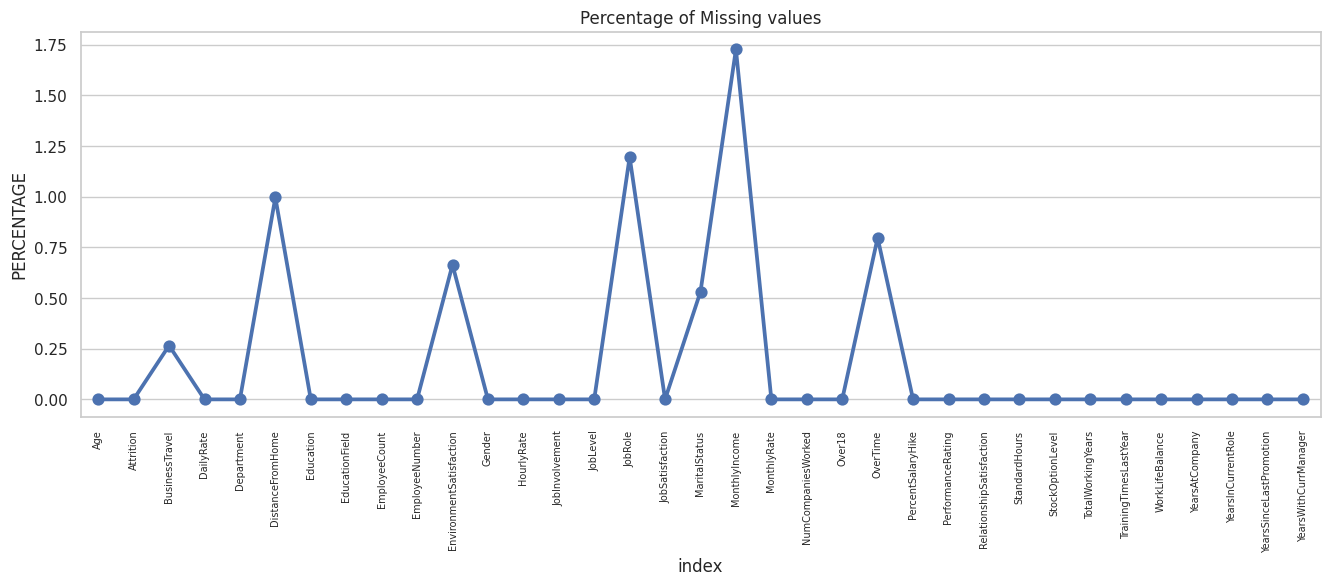

In [ ]:
Missing = pd.DataFrame((df.isnull().sum()) * 100 /df.shape[0]).reset_index()
plt.figure(figsize=(16,5))
sns.pointplot(x='index', y=0, data=Missing)
plt.xticks(rotation=90, fontsize=7)
plt.title("Percentage of Missing values")
plt.ylabel("PERCENTAGE")
plt.show()

In [ ]:
missing = df.isnull().sum()
print(missing[missing>0])
print(missing[missing>0] * 100 / df.shape[0])

BusinessTravel              4
DistanceFromHome           15
EnvironmentSatisfaction    10
JobRole                    18
MaritalStatus               8
MonthlyIncome              26
OverTime                   12
dtype: int64
BusinessTravel             0.265781
DistanceFromHome           0.996678
EnvironmentSatisfaction    0.664452
JobRole                    1.196013
MaritalStatus              0.531561
MonthlyIncome              1.727575
OverTime                   0.797342
dtype: float64


In [ ]:
df.BusinessTravel = df.BusinessTravel.replace('Unknown', np.nan)
df.BusinessTravel = df.groupby('JobRole')['BusinessTravel'].transform(
    lambda x:x.fillna(x.mode()[0] if not x.mode().empty else np.nan)
)
df.BusinessTravel = df.BusinessTravel.fillna(df.BusinessTravel.mode()[0])
df.BusinessTravel.value_counts()

,count
BusinessTravel,
Travel_Rarely,1074
Travel_Frequently,281
Non-Travel,150


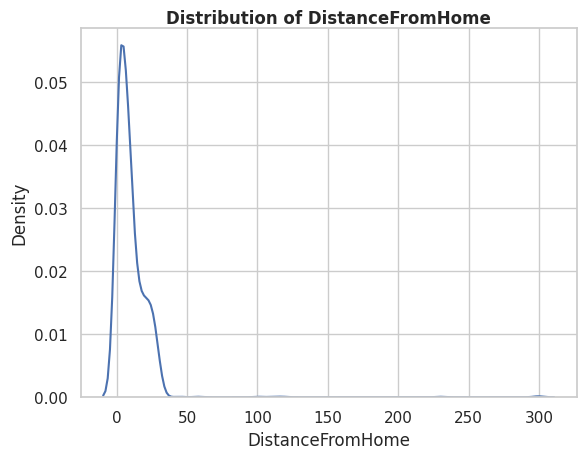

In [ ]:
sns.set_theme(style='whitegrid')
sns.kdeplot(df['DistanceFromHome'])
plt.title('Distribution of DistanceFromHome', fontweight='bold', fontsize=12, pad=3)
plt.show()

In [ ]:
#If the data is right skewed then we fill nan values with median, it is better than mean.
df.DistanceFromHome = df.groupby('Department')['DistanceFromHome'].transform(
    lambda x:x.fillna(x.median())
)
df.DistanceFromHome.isnull().sum()

np.int64(0)

In [ ]:
df.EnvironmentSatisfaction = df.groupby('Department')['EnvironmentSatisfaction'].transform(
   lambda x: x.fillna(x.mode()[0])
)
df.EnvironmentSatisfaction.isnull().sum()

np.int64(0)

In [ ]:
df.JobRole = df.groupby('Department')['JobRole'].transform(
    lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else np.nan
)
df.JobRole.isnull().sum()

np.int64(0)

In [ ]:
#According to the AgeGroup we can easily define their marital status so first we create AgeGroup new column then we fill MaritalStatus null values
bins = [0, 30, 45, 100]
labels = ['Young(0-30)', 'Mid(31-45)', 'Senior(46-100)']
df['AgeGroup'] = pd.cut(df['Age'], bins=bins, labels=labels)
df.MaritalStatus = df.groupby('AgeGroup')['MaritalStatus'].transform(
    lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else np.nan
)
df.MaritalStatus.isnull().sum()

/tmp/ipykernel_1035/452093015.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.MaritalStatus = df.groupby('AgeGroup')['MaritalStatus'].transform(


np.int64(0)

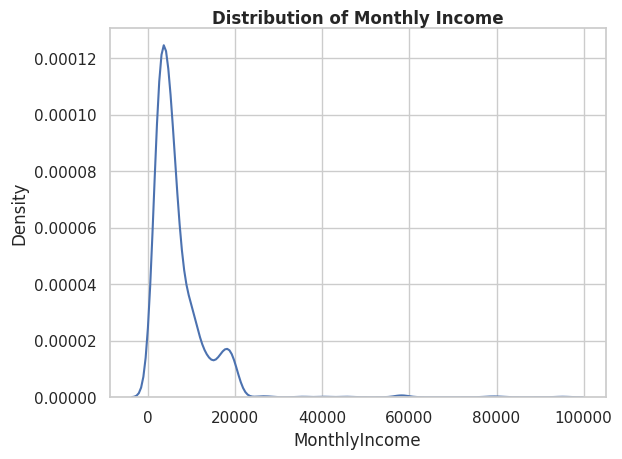

In [ ]:
sns.set_theme(style='whitegrid')
sns.kdeplot(df['MonthlyIncome'])
plt.title('Distribution of Monthly Income',fontsize=12, fontweight='bold', pad=3)
plt.show()

In [ ]:
#If the distribution is right skewed then we always consider median value to fill the null values.
df.MonthlyIncome = df.groupby(['JobRole', 'JobLevel'])['MonthlyIncome'].transform(
    lambda x: x.fillna(x.median())
)
df.MonthlyIncome.isnull().sum()

np.int64(0)

In [ ]:
df.OverTime = df.groupby('JobRole')['OverTime'].transform(
    lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else np.nan
)
df.OverTime.isnull().sum()

np.int64(0)

In [ ]:
df.isnull().sum()[df.isnull().sum() > 0]

,0


In [ ]:
df.YearsAtCompany.min() #Years in one company can't be negative

-1

In [ ]:
df.YearsAtCompany.replace(-1, np.nan, inplace=True)
df.YearsAtCompany.isnull().sum()

/tmp/ipykernel_1035/3532404412.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.YearsAtCompany.replace(-1, np.nan, inplace=True)


np.int64(3)

In [ ]:
df.YearsAtCompany = df.groupby('JobLevel')['YearsAtCompany'].transform(
    lambda x: x.fillna(x.median())
)
df.YearsAtCompany.isnull().sum()

np.int64(0)

#Univariate Analysis
Q10. Use descriptive statistics for Age, DailyRate, DistanceFromHome, HourlyRate, MonthlyIncome,
MonthlyRate, TotalWorkingYears, YearsAtCompany, and YearsWithCurrManager.<br>
Q11. Create histograms for at least five important numerical variables.<br>
Q12. Create boxplots for Age, MonthlyIncome, DistanceFromHome, and TotalWorkingYears.<br>
Q13. Analyze the distribution of Attrition, Gender, Department, JobRole, OverTime, and BusinessTravel.<br>

In [ ]:
# List of specified numerical columns
target_cols = ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome',
               'MonthlyRate', 'TotalWorkingYears', 'YearsAtCompany', 'YearsWithCurrManager']
# Generate descriptive statistics table
descriptive_stats = df[target_cols].describe().T
# Add Skewness and Median (50% is already in describe, but explicitly naming helps)
descriptive_stats['skewness'] = df[target_cols].skew()
# Display formatted dataframe
descriptive_stats[['count', 'mean', 'std', 'min', '50%', 'max', 'skewness']]

,count,mean,std,min,50%,max,skewness
Age,1505.0,36.964120,9.347035,16.0,36.0,75.000000,0.490032
DailyRate,1505.0,818.482884,452.037689,102.0,805.0,4337.015740,1.188224
DistanceFromHome,1505.0,9.992502,15.199138,1.0,7.0,300.088942,11.922647
HourlyRate,1505.0,65.974086,20.351924,30.0,66.0,100.000000,-0.034629
MonthlyIncome,1505.0,6882.758649,6653.671747,1009.0,4950.0,95182.820660,5.217370
MonthlyRate,1505.0,14348.412625,7122.254106,2094.0,14284.0,26999.000000,0.016481
TotalWorkingYears,1505.0,11.259801,7.784473,0.0,10.0,40.000000,1.127908
YearsAtCompany,1505.0,7.127575,6.565824,0.0,5.0,60.000000,2.430093
YearsWithCurrManager,1505.0,4.119601,3.555831,0.0,3.0,17.000000,0.832736


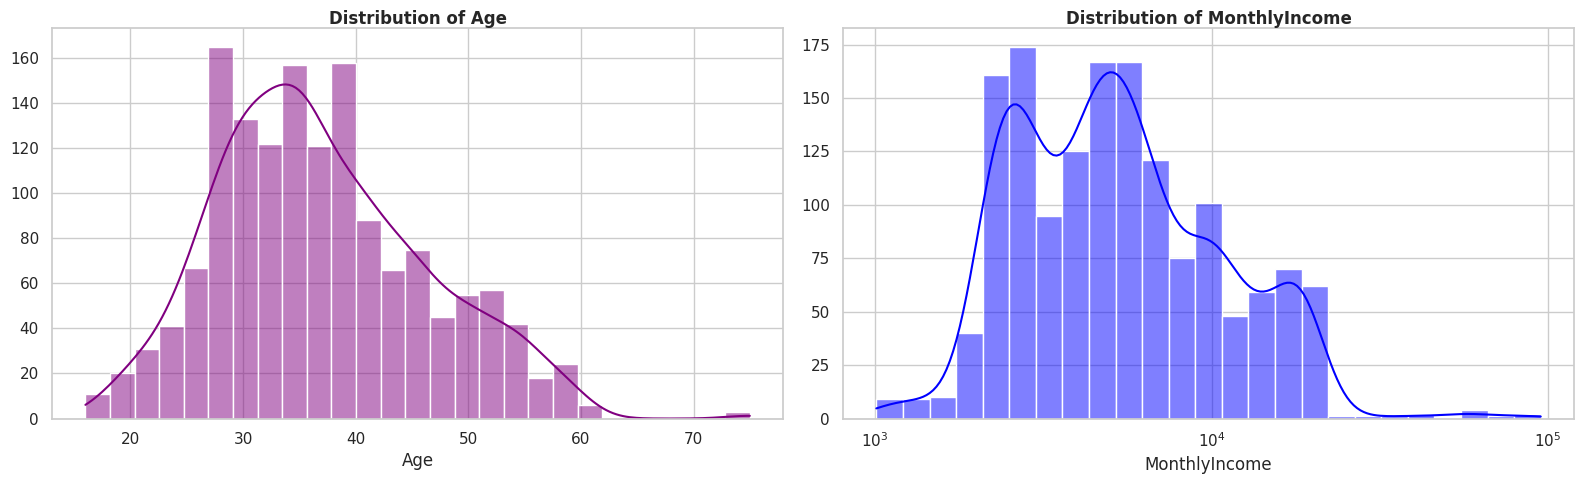

In [ ]:
from numpy._core.defchararray import index
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1,2, figsize=(16,5))
#---------Age Histogram--------------------
sns.histplot(data=df['Age'], kde=True, color='Purple', edgecolor='white', ax=axes[0])
axes[0].set_title('Distribution of Age', fontweight='bold', fontsize=12, pad=3)
axes[0].set_ylabel('')
axes[0].set_xlabel('Age')
#---------Monthly Income Histogram---------------
sns.histplot(data=df['MonthlyIncome'], kde=True,log_scale=True, color='blue', edgecolor='white', ax=axes[1])
axes[1].set_title('Distribution of MonthlyIncome', fontweight='bold', fontsize=12, pad=3)
axes[1].set_ylabel('')
axes[1].set_xlabel('MonthlyIncome')

plt.tight_layout()
plt.show()

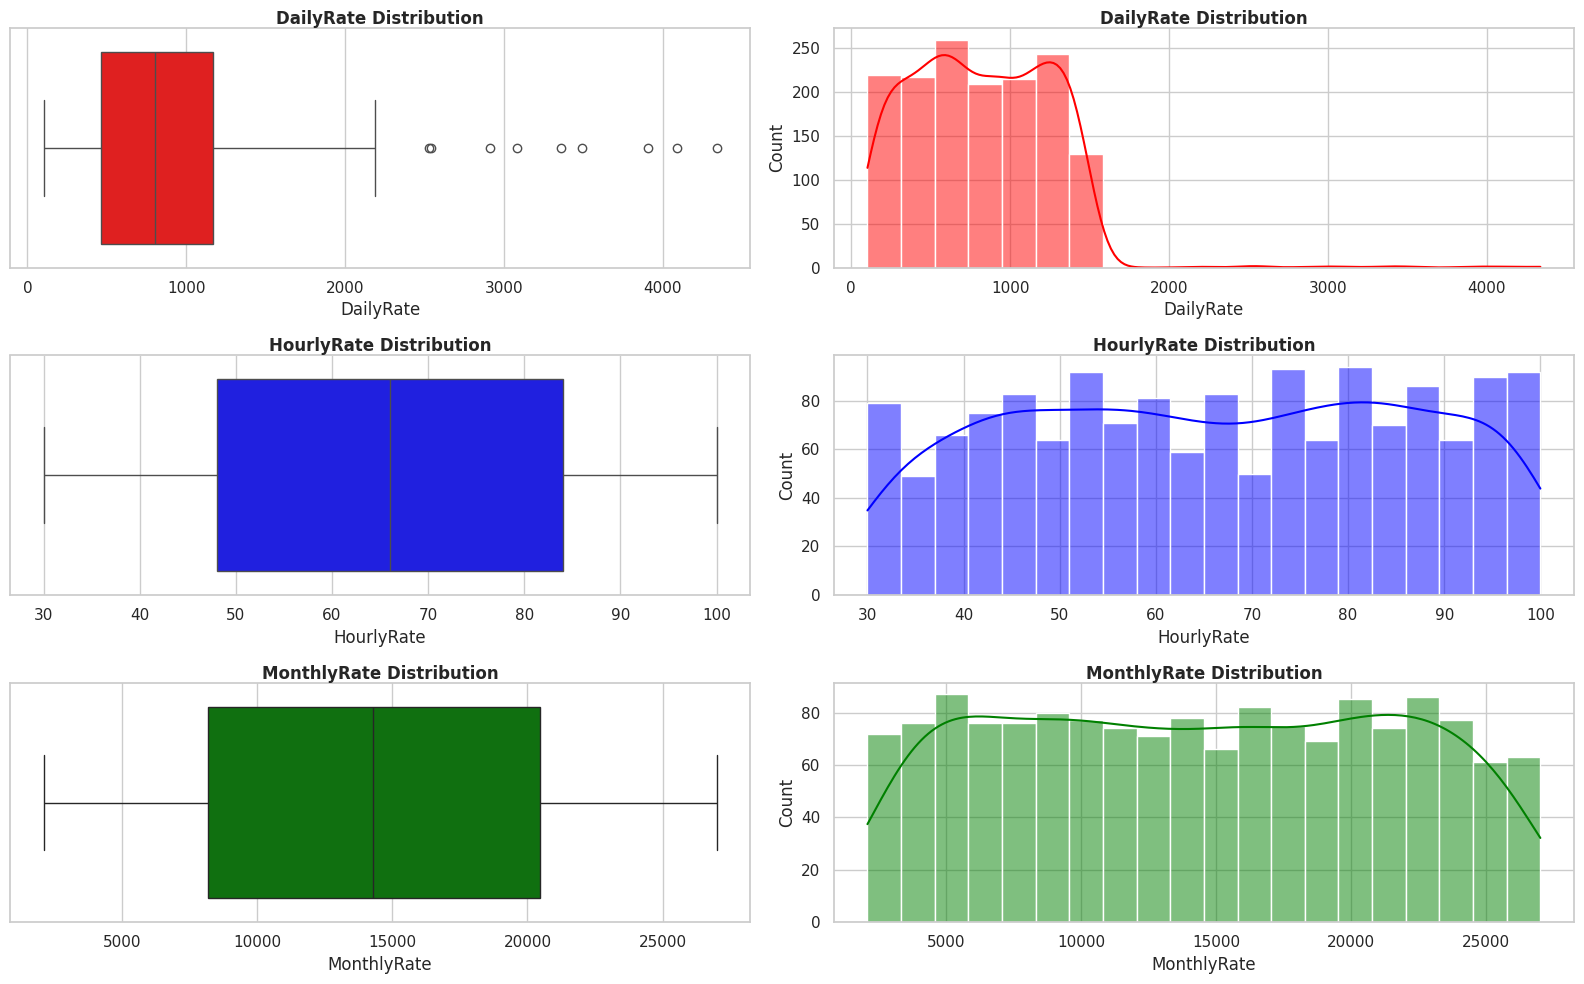

In [ ]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(3, 2, figsize=(16,10))
#-----DailyRate Boxplot & Histogram-------------
sns.boxplot(data=df, x='DailyRate', color='red', ax=axes[0,0])
axes[0,0].set_title('DailyRate Distribution', fontweight='bold', fontsize=12, pad=3)
sns.histplot(data=df['DailyRate'], kde=True, edgecolor='white', color='red', ax=axes[0,1], bins=20)
axes[0,1].set_title('DailyRate Distribution', fontweight='bold', fontsize=12, pad=3)
#-----HourlyRate Boxplot & Histogram---------------
sns.boxplot(data=df, x='HourlyRate', color='blue', ax=axes[1,0])
axes[1,0].set_title('HourlyRate Distribution', fontweight='bold', fontsize=12, pad=3)
sns.histplot(data=df['HourlyRate'], kde=True, edgecolor='white', color='blue', ax=axes[1,1], bins=20)
axes[1,1].set_title('HourlyRate Distribution', fontweight='bold', fontsize=12, pad=3)
#-----MonthlyRate Boxplot & Histogram---------------
sns.boxplot(data=df, x='MonthlyRate', color='green', ax=axes[2,0])
axes[2,0].set_title('MonthlyRate Distribution', fontweight='bold', fontsize=12, pad=3)
sns.histplot(data=df['MonthlyRate'], kde=True, edgecolor='white', color='green', ax=axes[2,1], bins=20)
axes[2,1].set_title('MonthlyRate Distribution', fontweight='bold', fontsize=12, pad=3)

plt.tight_layout()
plt.show()

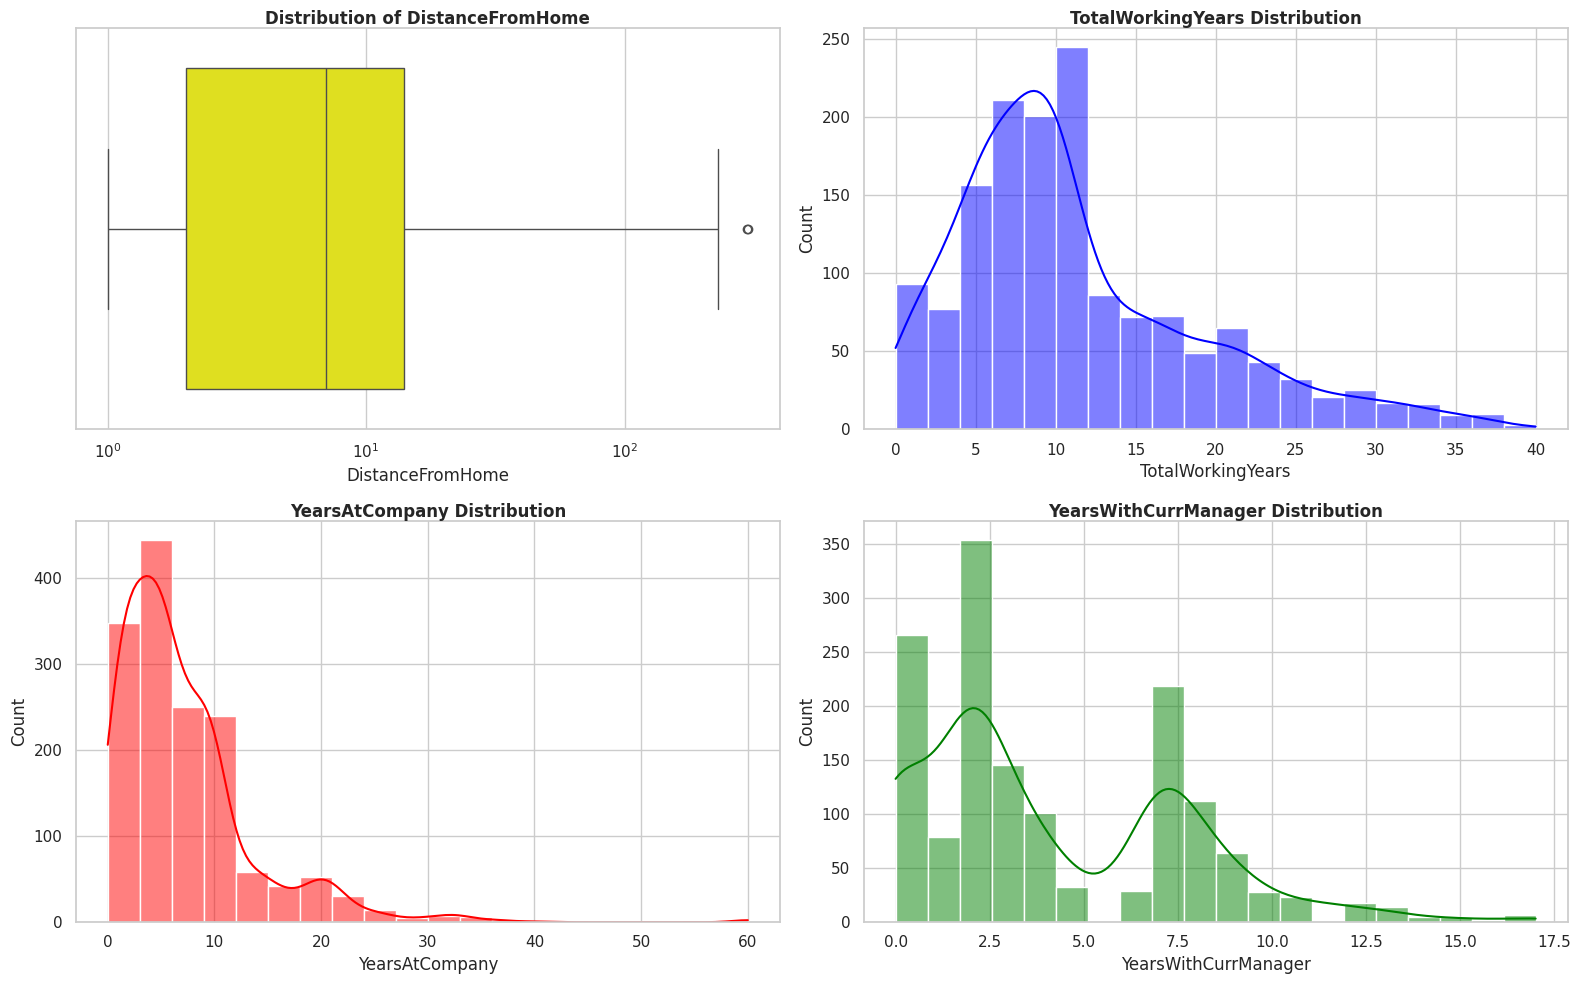

In [ ]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2,2, figsize=(16,10))
#--------DistanceFromHome Boxplot------------------
sns.boxplot(data=df, x='DistanceFromHome', color='yellow', ax=axes[0,0], log_scale=True)
axes[0,0].set_title('Distribution of DistanceFromHome', fontweight='bold', fontsize=12, pad=3)
#--------TotalWorkingYears Histogram----------------
sns.histplot(data=df, x='TotalWorkingYears', kde=True, color='blue', edgecolor='white', bins=20, ax=axes[0,1])
axes[0,1].set_title('TotalWorkingYears Distribution', fontweight='bold', fontsize=12, pad=3)
#--------YearsAtCompany Histogram-------------------
sns.histplot(data=df, x='YearsAtCompany', kde=True, color='red', edgecolor='white', bins=20, ax=axes[1,0])
axes[1,0].set_title('YearsAtCompany Distribution', fontweight='bold', fontsize=12, pad=3)
#---------YearsWithCurrManager Histogram----------------
sns.histplot(data=df, x='YearsWithCurrManager', kde=True, color='green', edgecolor='white', bins=20, ax=axes[1,1])
axes[1,1].set_title('YearsWithCurrManager Distribution', fontweight='bold', fontsize=12, pad=3)

plt.tight_layout()
plt.show()

Q13. Analyze the distribution of Attrition, Gender, Department, JobRole, OverTime, and BusinessTravel.

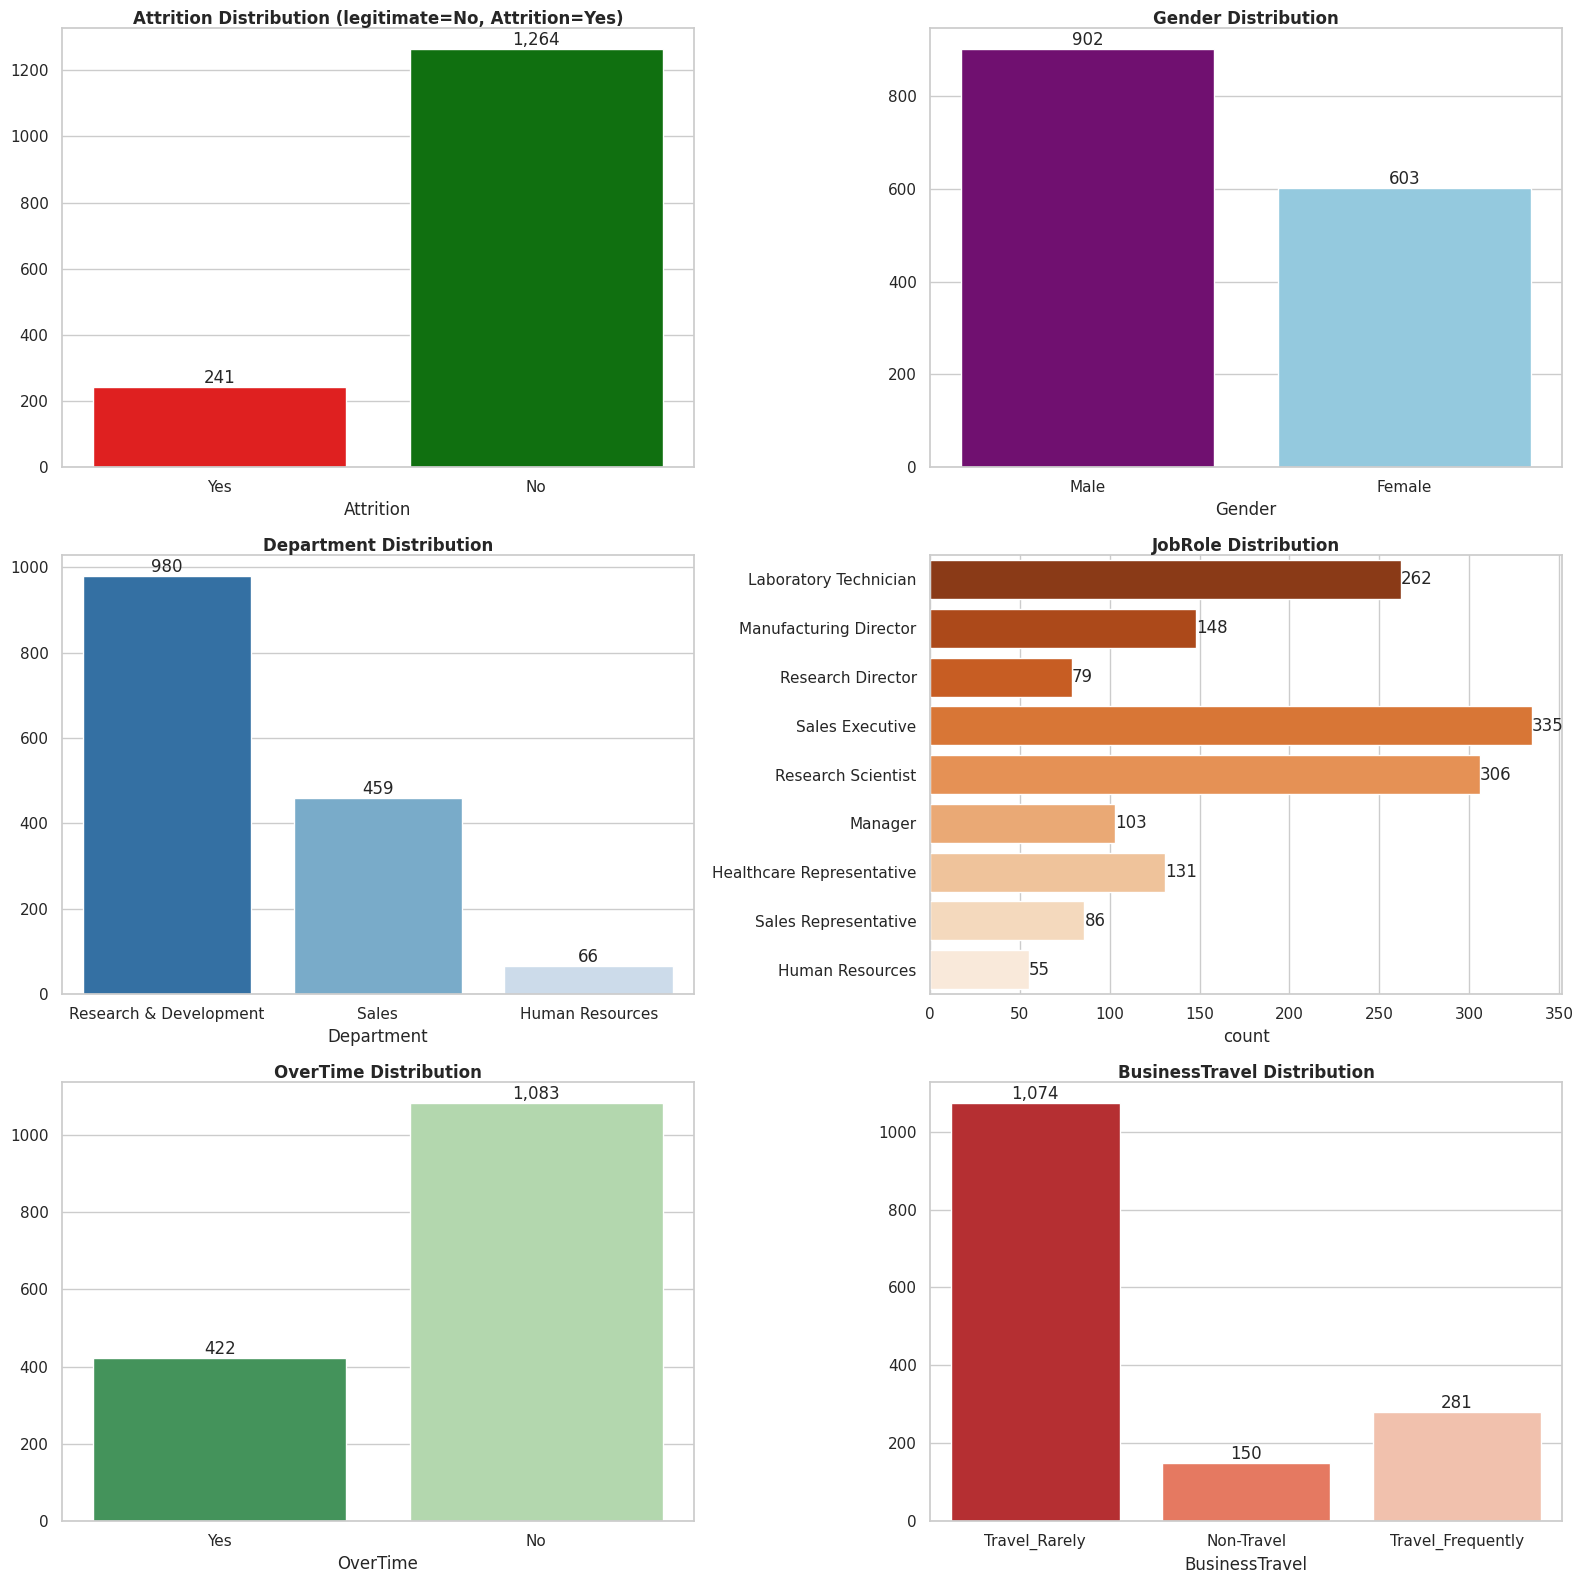

In [ ]:
#Categorical Univariate Analysis
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(3, 2, figsize=(16,16))
#--------Attrition Count Plot-------------
sns.countplot(data=df, x='Attrition', palette=['Red', 'Green'], hue='Attrition', ax=axes[0,0])
axes[0,0].set_title('Attrition Distribution (legitimate=No, Attrition=Yes)', fontweight='bold', fontsize=12, pad=3)
axes[0,0].set_ylabel('')
for container in axes[0,0].containers:
  axes[0,0].bar_label(container, fmt='{:,.0f}')
#---------Gender Count Plot----------------
sns.countplot(data=df, x='Gender', palette=['purple', 'skyblue'], hue='Gender', ax=axes[0,1])
axes[0,1].set_title('Gender Distribution', fontweight='bold', fontsize=12, pad=3)
axes[0,1].set_ylabel('')
for container in axes[0,1].containers:
  axes[0,1].bar_label(container, fmt='{:,.0f}')
#---------Department Count Plot---------------
sns.countplot(data=df, x='Department', palette='Blues_r', hue='Department', ax=axes[1,0])
axes[1,0].set_title('Department Distribution', fontweight='bold', fontsize=12, pad=3)
axes[1,0].set_ylabel('')
for container in axes[1,0].containers:
  axes[1,0].bar_label(container, fmt='{:,.0f}')
#----------JobRole Count Plot--------------------
sns.countplot(data=df, y='JobRole', palette='Oranges_r', hue='JobRole', ax=axes[1,1])
#axes[1,1].tick_params(axis='x', rotation=20)
axes[1,1].set_title('JobRole Distribution', fontweight='bold', fontsize=12, pad=3,)
axes[1,1].set_ylabel('')
for container in axes[1,1].containers:
  axes[1,1].bar_label(container, fmt='{:,.0f}')
#-----------OverTime Count Plot----------------------
sns.countplot(data=df, x='OverTime', palette='Greens_r', hue='OverTime', ax=axes[2,0])
axes[2,0].set_title('OverTime Distribution', fontweight='bold', fontsize=12, pad=3,)
axes[2,0].set_ylabel('')
for container in axes[2,0].containers:
  axes[2,0].bar_label(container, fmt='{:,.0f}')
#------------BusinessTravels--------------------
sns.countplot(data=df, x='BusinessTravel', palette='Reds_r', hue='BusinessTravel', ax=axes[2,1])
axes[2,1].set_title('BusinessTravel Distribution', fontweight='bold', fontsize=12, pad=3,)
axes[2,1].set_ylabel('')
for container in axes[2,1].containers:
  axes[2,1].bar_label(container, fmt='{:,.0f}')

plt.tight_layout()
plt.show()

#Attrition Analysis
Q14. Calculate the total number and percentage of employees who left versus stayed.<br>
Q15. Compare attrition rate by Department.<br>
Q16. Compare attrition rate by JobRole.<br>
Q17. Compare attrition rate by OverTime.<br>
Q18. Compare attrition rate by BusinessTravel.<br>
Q19. Compare attrition rate by MaritalStatus and Gender.<br>
Q20. Identify which groups have noticeably higher or lower observed attrition rates.<br>

In [ ]:
print(df.Attrition.value_counts())
print(df.Attrition.value_counts() * 100 / len(df))

Attrition
No     1264
Yes     241
Name: count, dtype: int64
Attrition
No     83.986711
Yes    16.013289
Name: count, dtype: float64


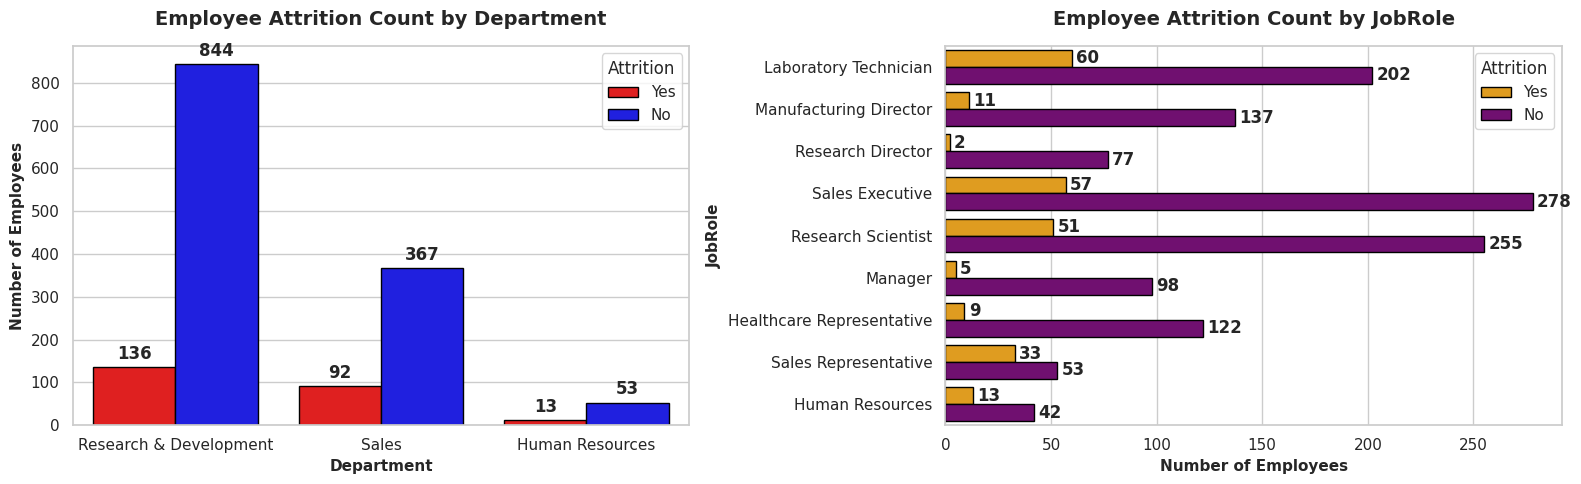

In [ ]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16,5))

#Attrition Count by Department
sns.countplot(data=df, x='Department', palette=['red', 'blue'], hue='Attrition', ax=axes[0], edgecolor='black')
axes[0].set_title('Employee Attrition Count by Department', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Department', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Number of Employees', fontsize=11, fontweight='bold')

for container in axes[0].containers:
  axes[0].bar_label(container, fmt='{:,.0f}', fontweight='bold', padding=3)

#Attrition Count by JobRole
sns.countplot(data=df, y='JobRole', palette=['orange', 'purple'], hue='Attrition', ax=axes[1], edgecolor='black')
axes[1].set_title('Employee Attrition Count by JobRole', fontsize=14, fontweight='bold', pad=15)
axes[1].set_ylabel('JobRole', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Number of Employees', fontsize=11, fontweight='bold')

for container in axes[1].containers:
  axes[1].bar_label(container, fmt='{:,.0f}', fontweight='bold', padding=3)

plt.tight_layout()
plt.show()

In [ ]:
df['Attrition'] = df['Attrition'].map({'Yes':1,'No':0})
JobRole_Summary = df.groupby('JobRole').agg(
    total_employees=('Attrition', 'count'),
    employees_attrition=('Attrition', 'sum'),
    employees_attrition_rate=('Attrition', lambda x: x.mean() * 100),
).sort_values(by='employees_attrition_rate', ascending=False).reset_index()
JobRole_Summary

,JobRole,total_employees,employees_attrition,employees_attrition_rate
0,Sales Representative,86,33,38.372093
1,Human Resources,55,13,23.636364
2,Laboratory Technician,262,60,22.900763
3,Sales Executive,335,57,17.014925
4,Research Scientist,306,51,16.666667
5,Manufacturing Director,148,11,7.432432
6,Healthcare Representative,131,9,6.870229
7,Manager,103,5,4.854369
8,Research Director,79,2,2.531646


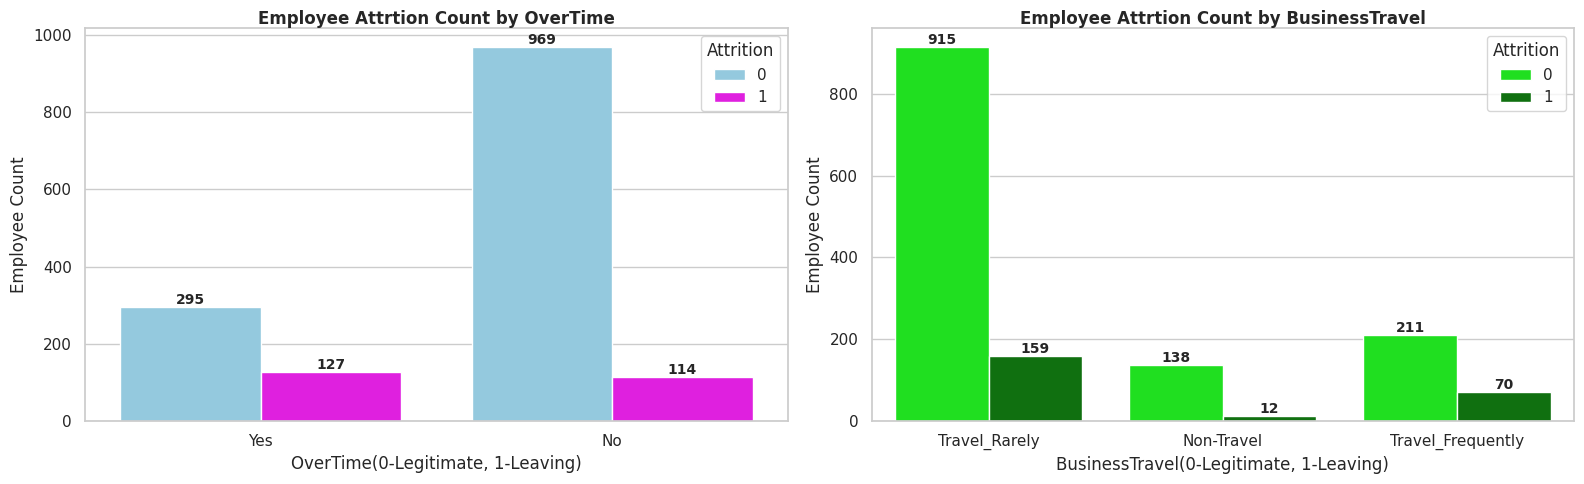

In [ ]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1,2,figsize=(16,5))

#Attrition count by OverTime
sns.countplot(data=df, x='OverTime', hue='Attrition', palette=['skyblue', 'magenta'], ax=axes[0],edgecolor='white')
axes[0].set_title('Employee Attrtion Count by OverTime', fontweight='bold', fontsize=12, pad=3)
axes[0].set_xlabel('OverTime(0-Legitimate, 1-Leaving)', fontsize=12)
axes[0].set_ylabel('Employee Count', fontsize=12)

for container in axes[0].containers:
  axes[0].bar_label(container, fmt='{:,.0f}', fontweight='bold', fontsize=10)

#Attrition count by
sns.countplot(data=df, x='BusinessTravel', hue='Attrition', palette=['lime', 'green'], ax=axes[1],edgecolor='white')
axes[1].set_title('Employee Attrtion Count by BusinessTravel', fontweight='bold', fontsize=12, pad=3)
axes[1].set_xlabel('BusinessTravel(0-Legitimate, 1-Leaving)', fontsize=12)
axes[1].set_ylabel('Employee Count', fontsize=12)

for container in axes[1].containers:
  axes[1].bar_label(container, fmt='{:,.0f}', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

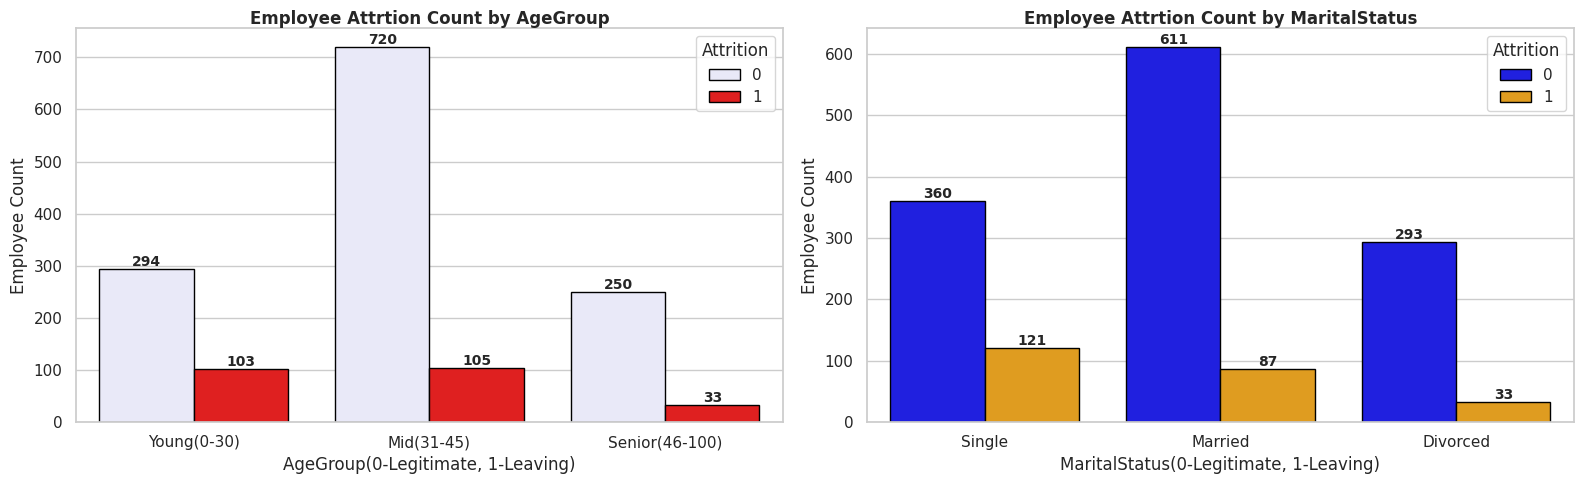

In [ ]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1,2,figsize=(16,5))

#Attrition count by AgeGroup
sns.countplot(data=df, x='AgeGroup', hue='Attrition', palette=['lavender', 'red'], ax=axes[0],edgecolor='black')
axes[0].set_title('Employee Attrtion Count by AgeGroup', fontweight='bold', fontsize=12, pad=3)
axes[0].set_xlabel('AgeGroup(0-Legitimate, 1-Leaving)', fontsize=12)
axes[0].set_ylabel('Employee Count', fontsize=12)

for container in axes[0].containers:
  axes[0].bar_label(container, fmt='{:,.0f}', fontweight='bold', fontsize=10)

#Attrition count by MaritalStatus
sns.countplot(data=df, x='MaritalStatus', hue='Attrition', palette=['blue', 'orange'], ax=axes[1],edgecolor='black')
axes[1].set_title('Employee Attrtion Count by MaritalStatus', fontweight='bold', fontsize=12, pad=3)
axes[1].set_xlabel('MaritalStatus(0-Legitimate, 1-Leaving)', fontsize=12)
axes[1].set_ylabel('Employee Count', fontsize=12)

for container in axes[1].containers:
  axes[1].bar_label(container, fmt='{:,.0f}', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

#Numerical Relationships
Q21. Compare MonthlyIncome between employees who left and stayed.<br>
Q22. Compare Age, DistanceFromHome, TotalWorkingYears, YearsAtCompany, and JobSatisfaction by
Attrition.<br>
Q23. Create suitable visualizations for at least four numerical variables against Attrition.<br>
Q24. Investigate whether YearsAtCompany and YearsInCurrentRole show an apparent relationship with
attrition.<br>

In [ ]:
Income_comparison = df.groupby('Attrition')['MonthlyIncome'].agg(
    ['count', 'mean', 'median', 'std']
).rename(index={0:'Stayed (No)', 1:'Left (Yes)'})
print(Income_comparison)

             count         mean  median          std
Attrition                                           
Stayed (No)   1264  7171.627257  5215.0  6495.729287
Left (Yes)     241  5367.696739  3339.0  7255.396197


In [ ]:
new_df = df[df['MonthlyIncome']<40000]

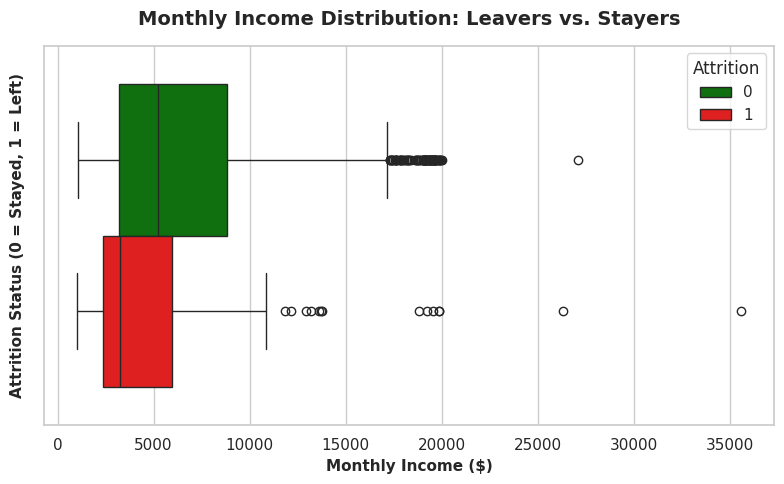

In [ ]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(8,5))
ax = sns.boxplot(
    data=new_df,
    x='MonthlyIncome',
    palette=['green', 'red'],
    hue='Attrition'
)
plt.title('Monthly Income Distribution: Leavers vs. Stayers', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Attrition Status (0 = Stayed, 1 = Left)', fontsize=11, fontweight='bold')
plt.xlabel('Monthly Income ($)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

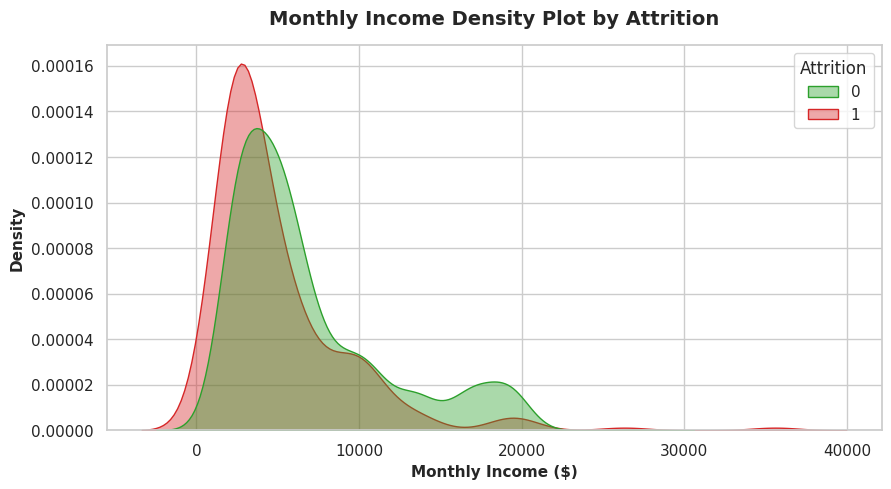

In [ ]:
plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=new_df,
    x='MonthlyIncome',
    hue='Attrition',
    common_norm=False,
    fill=True,
    palette=['#2ca02c', '#d62728'],
    alpha=0.4
)
plt.title('Monthly Income Density Plot by Attrition', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Monthly Income ($)', fontsize=11, fontweight='bold')
plt.ylabel('Density', fontsize=11, fontweight='bold')
plt.show()

In [ ]:
age_comparison = df.groupby('Attrition')['Age'].agg(
    ['count','mean', 'median', 'std']
).rename(index={0:'Stayed (No)', 1:'Left (Yes)'})
print('-----Age Comparison--------\n',age_comparison,'\n')

distance_comparison = df.groupby('Attrition')['DistanceFromHome'].agg(
    ['count', 'mean', 'median', 'std']
).rename({0:'Stayed (No)', 1:'Left (Yes)'})
print('------DistanceFromHome Comparison----------\n', distance_comparison,'\n')

working_comparison = df.groupby('Attrition')['TotalWorkingYears'].agg(
    ['count', 'mean', 'median', 'std']
).rename({0:'Stayed (No)',1:'Left (Yes)'})
print('-------TotalWorkingYears Comparison---------\n', working_comparison, '\n')

years_comparison = df.groupby('Attrition')['YearsAtCompany'].agg(
    ['count', 'mean', 'median', 'std']
).rename({0:'Stayed (No)', 1:'Left (Yes)'})
print('--------YearsAtCompany Comparison-----------\n', years_comparison, '\n')

job_satisfaction_comparison = df.groupby('Attrition')['JobSatisfaction'].agg(
    ['count', 'mean', 'median', 'std']
).rename({0:'Stayed (No)', 1:'Left (Yes)'})
print('-----------JobSatisfaction Comparison--------------\n', job_satisfaction_comparison,'\n')

-----Age Comparison--------
              count       mean  median       std
Attrition                                      
Stayed (No)   1264  37.640823    36.0  9.144955
Left (Yes)     241  33.414938    31.0  9.609133 

------DistanceFromHome Comparison----------
              count       mean  median        std
Attrition                                       
Stayed (No)   1264   9.798561     7.0  15.970088
Left (Yes)     241  11.009687     9.0  10.211846 

-------TotalWorkingYears Comparison---------
              count       mean  median       std
Attrition                                      
Stayed (No)   1264  11.844937    10.0  7.767994
Left (Yes)     241   8.190871     7.0  7.137115 

--------YearsAtCompany Comparison-----------
              count      mean  median       std
Attrition                                     
Stayed (No)   1264  7.510285     6.0  6.615552
Left (Yes)     241  5.120332     3.0  5.918020 

-----------JobSatisfaction Comparison--------------
      

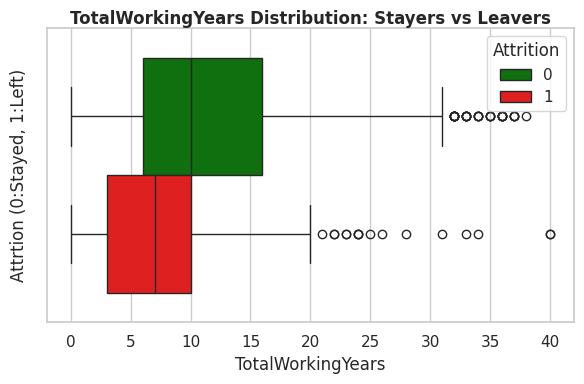

In [ ]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(6,4))
ax = sns.boxplot(data=df, x='TotalWorkingYears', palette=['green', 'red'], hue='Attrition')
plt.title('TotalWorkingYears Distribution: Stayers vs Leavers', fontsize=12, fontweight='bold', pad=3)
plt.ylabel('Attrtion (0:Stayed, 1:Left)', fontsize=12)
plt.xlabel('TotalWorkingYears', fontsize=12)
plt.tight_layout()
plt.show()

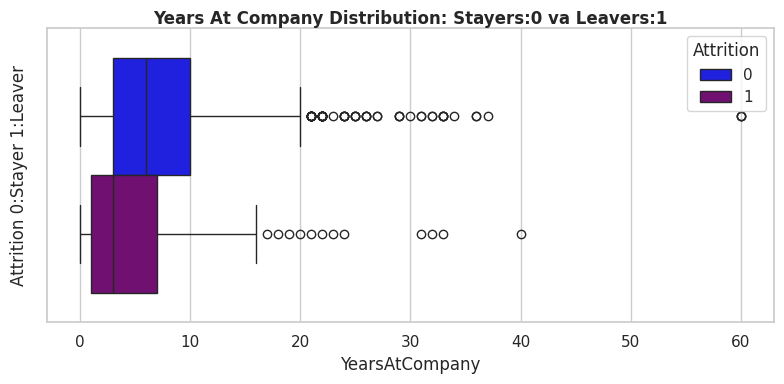

In [ ]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(8,4))
ax = sns.boxplot(data=df, x='YearsAtCompany', palette=['Blue', 'Purple'], hue='Attrition')
plt.title('Years At Company Distribution: Stayers:0 va Leavers:1', fontsize=12, fontweight='bold', pad=3)
plt.ylabel('Attrition 0:Stayer 1:Leaver', fontsize=12)
plt.xlabel('YearsAtCompany', fontsize=12)
plt.tight_layout()
plt.show()

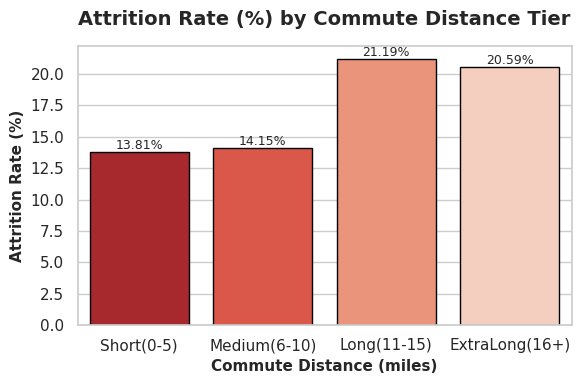

In [ ]:
bins = [0, 5, 10, 15, float('inf')]
labels = ['Short(0-5)', 'Medium(6-10)', 'Long(11-15)', 'ExtraLong(16+)']
df['DistanceGroup'] = pd.cut(df['DistanceFromHome'], bins=bins, labels=labels)
sns.set_theme(style='whitegrid')
commute_attrition = df.groupby('DistanceGroup', observed=False)['Attrition'].mean().reset_index()
commute_attrition.Attrition *= 100
plt.figure(figsize=(6, 4))
ax = sns.barplot(
    data=commute_attrition,
    x='DistanceGroup',
    y='Attrition',
    palette='Reds_r',
    hue='DistanceGroup',
    edgecolor='black'
)
plt.title('Attrition Rate (%) by Commute Distance Tier', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Commute Distance (miles)', fontsize=11, fontweight='bold')
plt.ylabel('Attrition Rate (%)', fontsize=11, fontweight='bold')

for container in ax.containers:
  ax.bar_label(container, fmt='%.2f%%', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
#tenure_col comparison
tenure_col = ['YearsAtCompany', 'YearsInCurrentRole']
tenure_summary = df.groupby('Attrition')[tenure_col].agg(
  ['mean', 'median']
).rename(index={0:"Stayed (0)", 1:'Left (1)'})
tenure_summary

YearsAtCompany        YearsInCurrentRole       
                     mean median               mean median
Attrition                                                 
Stayed (0)       7.510285    6.0           4.500000    3.0
Left (1)         5.120332    3.0           2.904564    2.0

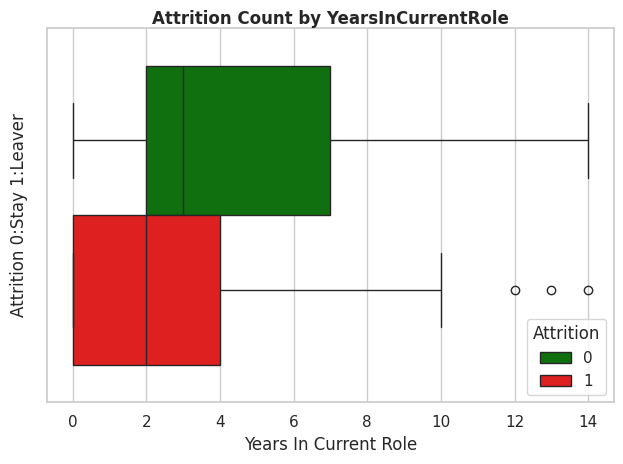

In [ ]:
sns.set_theme(style='whitegrid')
ax = sns.boxplot(data=df[df['YearsInCurrentRole'] < 15], x='YearsInCurrentRole', palette=['green', 'red'], hue='Attrition')
plt.title('Attrition Count by YearsInCurrentRole', fontsize=12, fontweight='bold', pad=3)
plt.ylabel('Attrition 0:Stay 1:Leaver', fontsize=12)
plt.xlabel('Years In Current Role', fontsize=12)
plt.tight_layout()
plt.show()

#Satisfaction & Work Conditions
Q25. Analyze EnvironmentSatisfaction, JobInvolvement, JobSatisfaction, RelationshipSatisfaction, and
WorkLifeBalance.<br>
Q26. Calculate attrition rate for each satisfaction level.<br>
Q27. Investigate the relationship between OverTime and JobSatisfaction.<br>
Q28. Investigate whether StockOptionLevel appears related to Attrition.<br>

In [ ]:
satisfaction_cols = ['EnvironmentSatisfaction', 'JobInvolvement', 'JobSatisfaction', 'RelationshipSatisfaction', 'WorkLifeBalance']
for col in satisfaction_cols:
  print(f"------Satisfaction Summary of {col}-----------")
  summary = df.groupby(col)['Attrition'].agg(
      total_employees='count',
      leavers='sum',
      attrition_rate=lambda x: x.mean() * 100
  ).round(2)
  print(summary)

------Satisfaction Summary of EnvironmentSatisfaction-----------
                         total_employees  leavers  attrition_rate
EnvironmentSatisfaction                                          
1.0                                  288       73           25.35
2.0                                  289       42           14.53
3.0                                  462       63           13.64
4.0                                  466       63           13.52
------Satisfaction Summary of JobInvolvement-----------
                total_employees  leavers  attrition_rate
JobInvolvement                                          
1                            83       28           33.73
2                           383       72           18.80
3                           892      127           14.24
4                           147       14            9.52
------Satisfaction Summary of JobSatisfaction-----------
                 total_employees  leavers  attrition_rate
JobSatisfaction           

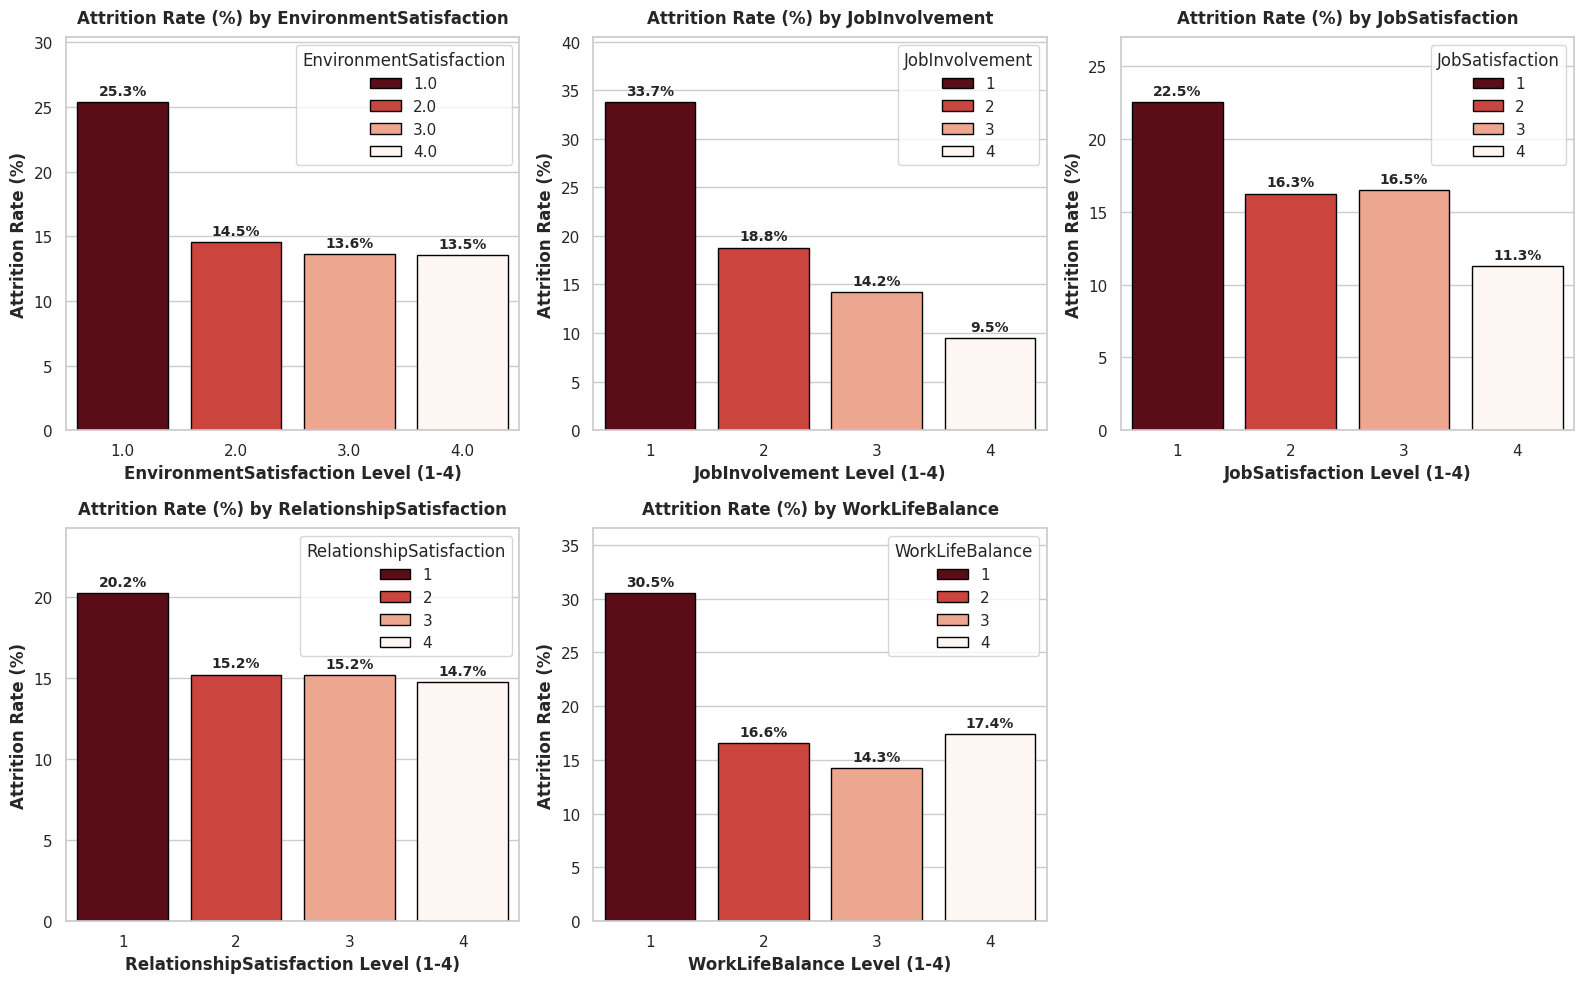

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

satisfaction_cols = [
    'EnvironmentSatisfaction', 'JobInvolvement',
    'JobSatisfaction', 'RelationshipSatisfaction', 'WorkLifeBalance'
]

for i, col in enumerate(satisfaction_cols):
    # Calculate percentage attrition per category level
    sat_attr = df.groupby(col, observed=False)['Attrition'].mean().reset_index()
    sat_attr['Attrition'] *= 100  # Convert to percentage

    # Plot bar chart (Removed legend=False which was crashing the loop)
    sns.barplot(
        data=sat_attr, x=col, y='Attrition',
        hue=col, palette='Reds_r', ax=axes[i], edgecolor='black'
    )

    axes[i].set_title(f'Attrition Rate (%) by {col}', fontweight='bold', fontsize=12, pad=10)
    axes[i].set_xlabel(f'{col} Level (1-4)', fontweight='bold')
    axes[i].set_ylabel('Attrition Rate (%)', fontweight='bold')

    # Safely handle y-limit
    max_y = sat_attr['Attrition'].max()
    axes[i].set_ylim(0, max_y * 1.2 if max_y > 0 else 10)

    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='{:.1f}%', padding=3, fontweight='bold', fontsize=10)

# Hide the 6th empty subplot frame since there are 5 metrics
if len(satisfaction_cols) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

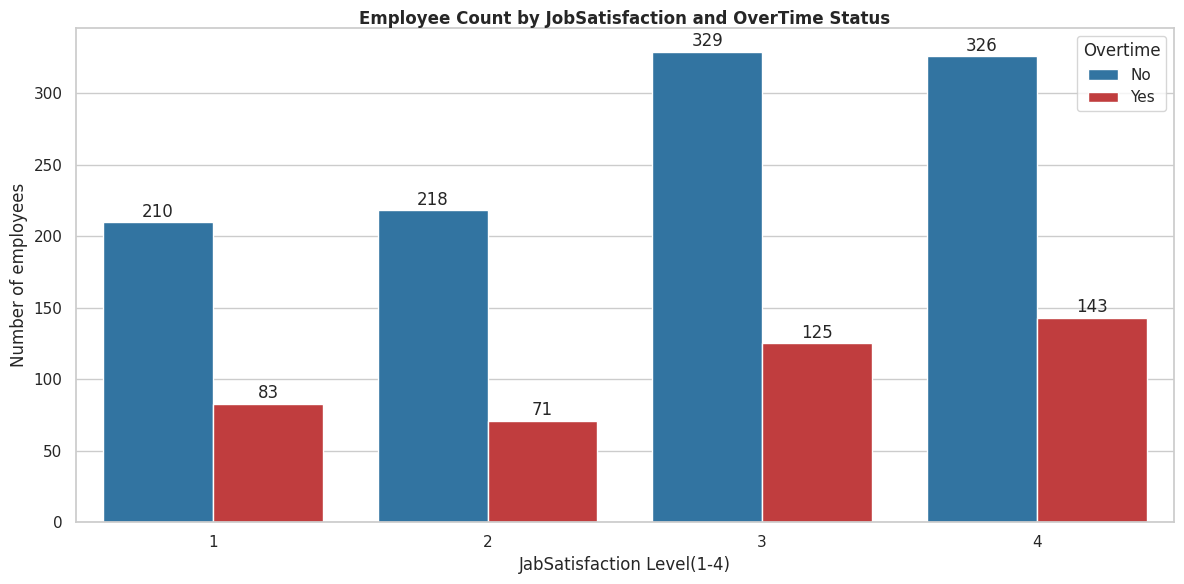

In [ ]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12, 6))
ax = sns.countplot(
    data=df, x='JobSatisfaction', hue='OverTime',
    palette={'Yes': '#d62728', 'No': '#1f77b4'}
)
ax.set_title('Employee Count by JobSatisfaction and OverTime Status', fontweight='bold', fontsize=12, pad=3)
ax.set_ylabel('Number of employees')
ax.set_xlabel('JabSatisfaction Level(1-4)')

for container in ax.containers:
  ax.bar_label(container, fmt='{:,.0f}', padding=1)

plt.legend(title='Overtime',loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
stock_summary = df.groupby('StockOptionLevel')['Attrition'].agg(
    num_employees='count',
    leavers='sum',
    attrition_rate= lambda x:x.mean()*100
).sort_values(by='attrition_rate', ascending=False).reset_index()
print(stock_summary)

   StockOptionLevel  num_employees  leavers  attrition_rate
0                 0            652      158       24.233129
1                 3             85       15       17.647059
2                 1            608       56        9.210526
3                 2            160       12        7.500000


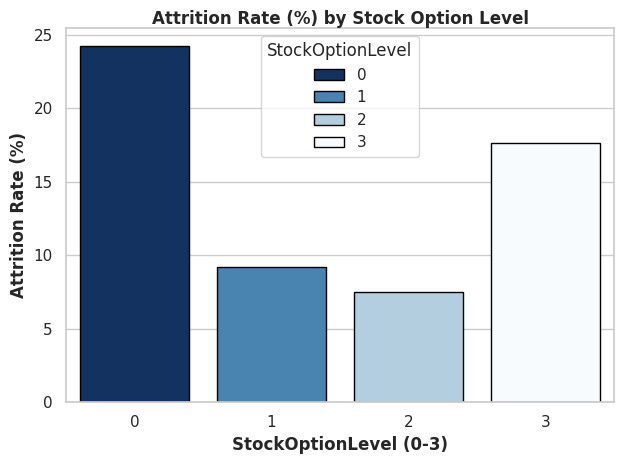

In [ ]:
sns.set_theme(style='whitegrid')
ax = sns.barplot(data=stock_summary, x='StockOptionLevel', y='attrition_rate', hue='StockOptionLevel', palette='Blues_r', edgecolor='black')
plt.title('Attrition Rate (%) by Stock Option Level', fontsize=12, fontweight='bold', pad=3)
plt.ylabel('Attrition Rate (%)', fontweight='bold')
plt.xlabel('StockOptionLevel (0-3)', fontweight='bold')
plt.tight_layout()
plt.show()

#Correlation Analysis
Q29. Create a correlation matrix for numerical variables.<br>
Q30. Visualize the correlation matrix using a heatmap.<br>
Q31. Identify the strongest positive and negative relationships.<br>
Q32. Check whether any variables are redundant or nearly constant.<br>

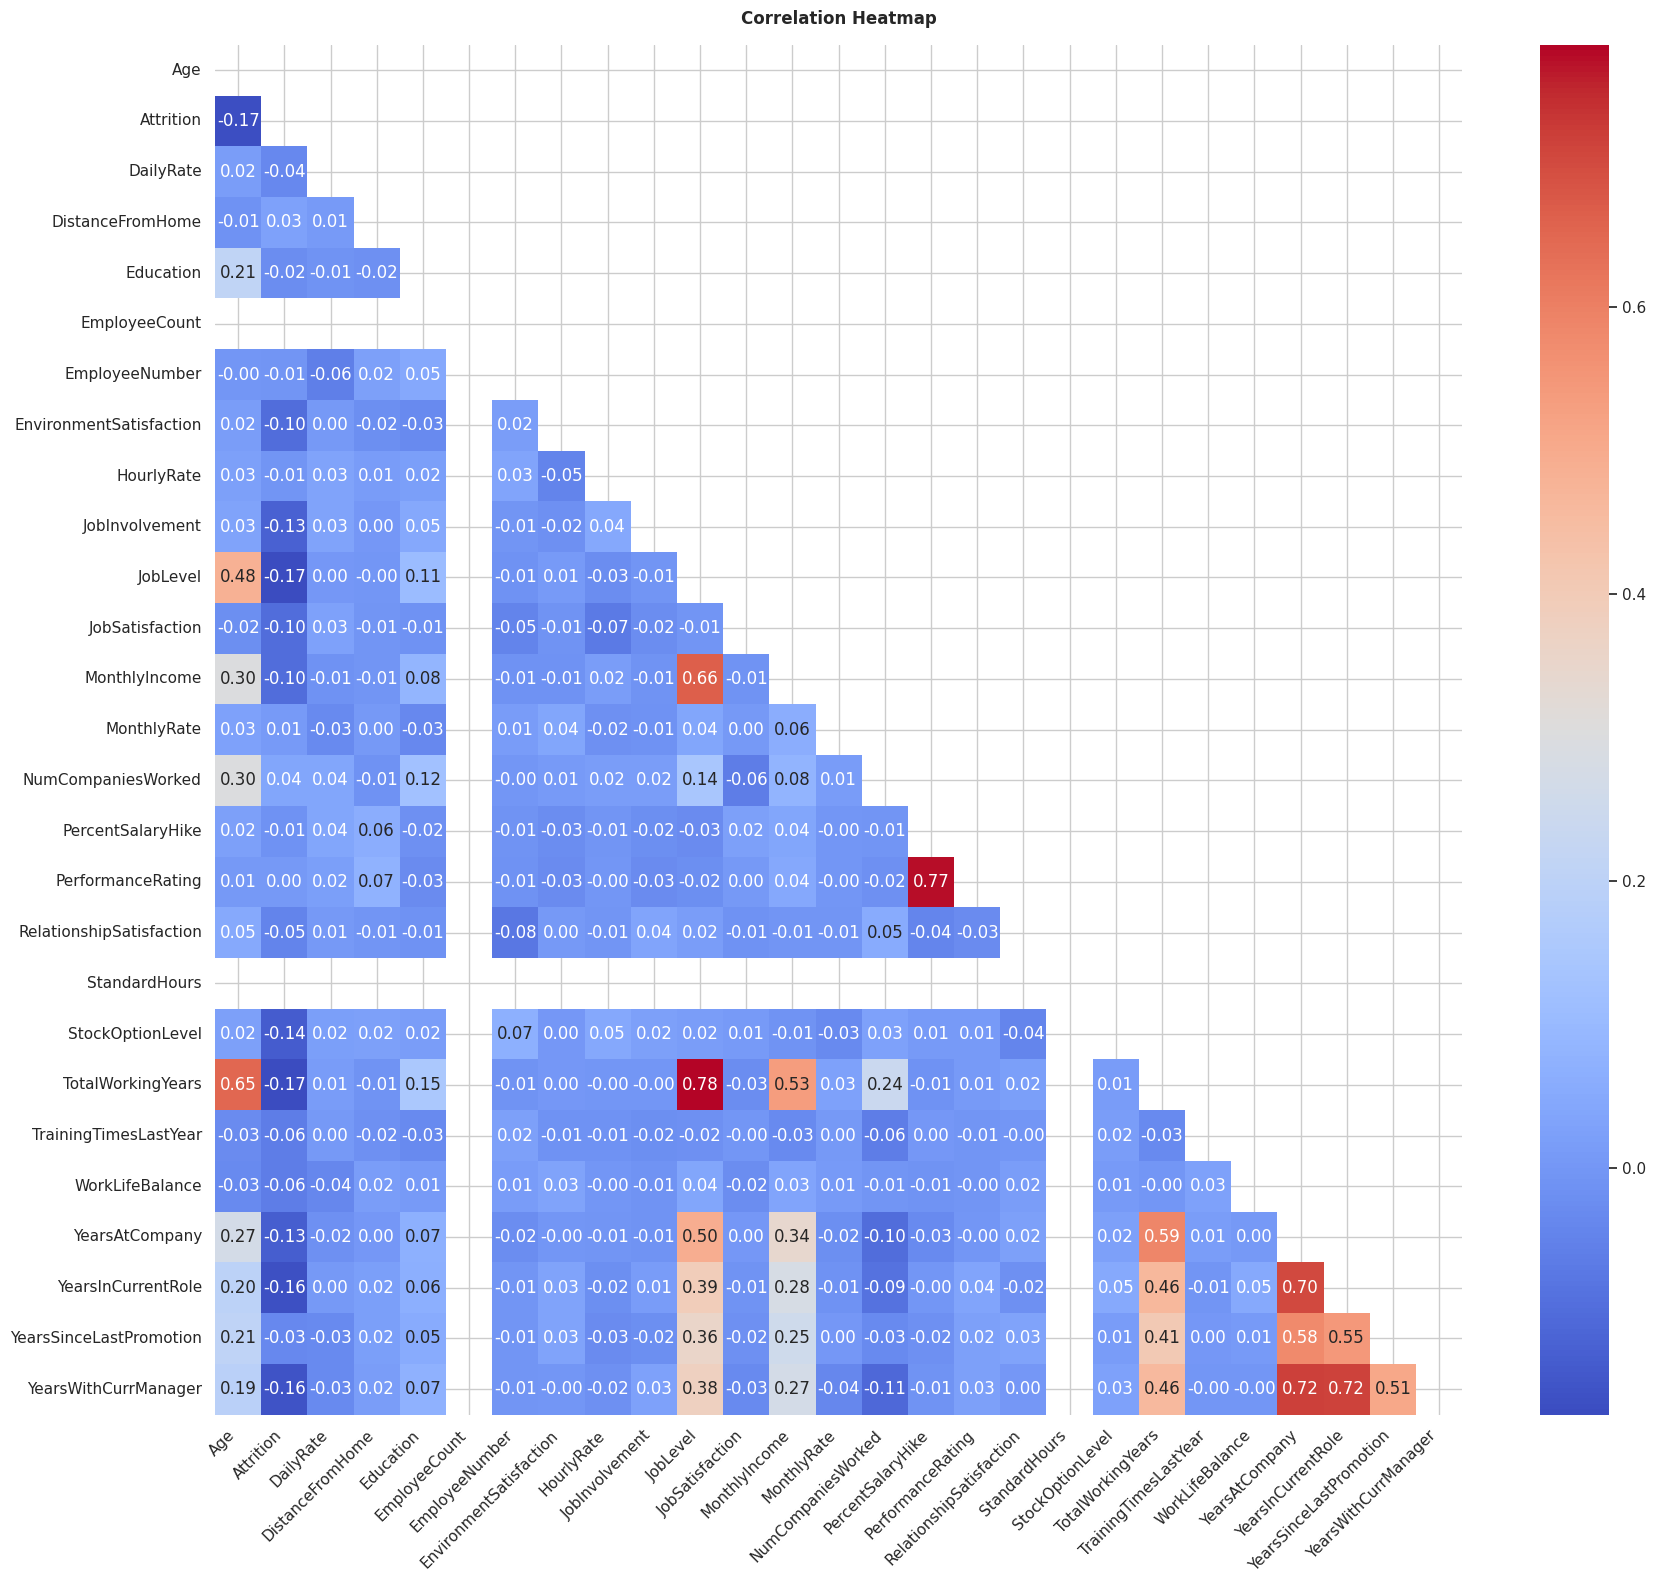

In [ ]:
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(18,16))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(mask=mask,data=corr_matrix, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Correlation Heatmap', fontsize=12,fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#Strongest Positive relationships are TotalWorkingYears v/s JobLevel, PerformanceRating v/s PercentageSalaryHike
#Nearly Constant variables are -- EmployeeCount & StandardHours -- can be dropped
df.drop(columns=['EmployeeCount', 'StandardHours'], inplace=True)

#Outlier & Logic Checks
Q33. Use the IQR method to identify outliers in MonthlyIncome and DistanceFromHome.<br> Q34. Check whether Age contains unrealistic values.<br>
Q35. Check whether YearsAtCompany can logically exceed TotalWorkingYears.<br> Q36. Investigate other combinations where one variable should logically relate to another.<br>

In [ ]:
cols = ['MonthlyIncome', 'DistanceFromHome']
print(df[cols].describe())
monthlyincome_IQR = 8500 - 2911
distancefromhome_IQR = 14 - 2
#upper and lower bound for income
income_upper = 8500 + 1.5 * monthlyincome_IQR
income_lower = 2911 - 1.5 * monthlyincome_IQR

#upper and lower bound for distance
distance_upper = 14 + 1.5 * distancefromhome_IQR
distance_lower = 2 - 1.5 * distancefromhome_IQR

income_outliers = df[(df['MonthlyIncome'] < income_lower) | (df['MonthlyIncome'] > income_upper)]
distance_outliers = df[(df['DistanceFromHome'] < income_lower) | (df['DistanceFromHome'] > income_upper)]
print('MonthlyIncome Outliers Shape:',income_outliers.shape)
print('DistanceFromHome Outliers Shape:', distance_outliers.shape)

new_df = df[(df['MonthlyIncome'] >= income_lower) | (df['MonthlyIncome'] <= income_upper)]
new_df.shape

       MonthlyIncome  DistanceFromHome
count    1505.000000       1505.000000
mean     6882.758649          9.992502
std      6653.671747         15.199138
min      1009.000000          1.000000
25%      2911.000000          2.000000
50%      4950.000000          7.000000
75%      8500.000000         14.000000
max     95182.820660        300.088942
MonthlyIncome Outliers Shape: (114, 35)
DistanceFromHome Outliers Shape: (0, 35)


(1505, 35)

In [ ]:
print('Invalid Values',df[df['Age'] == 16].shape)
new_df = new_df[new_df['Age'] >= 18] #Removed invalid values

Invalid Values (3, 35)


In [ ]:
print('Invalid Values', df[df['YearsAtCompany'] > df['TotalWorkingYears']].shape)
new_df = new_df[new_df['YearsAtCompany'] <= new_df['TotalWorkingYears']] #Removed invalid values

Invalid Values (3, 35)


In [ ]:
print('Invalid Values', df[df['YearsInCurrentRole'] > df['YearsAtCompany']].shape)
print('Invalid Values', df[df['YearsSinceLastPromotion'] > df['YearsAtCompany']].shape)
print('Invalid Values', df[df['YearsWithCurrManager'] > df['YearsAtCompany']].shape)
print('Invalid Values', df[df['TotalWorkingYears'] > (df['Age'] - 18)].shape)
new_df = new_df[new_df['TotalWorkingYears'] <= (new_df['Age'] - 18)] #Removed invalid values

Invalid Values (0, 35)
Invalid Values (0, 35)
Invalid Values (0, 35)
Invalid Values (3, 35)


#Final EDA Report
Q43. Write 10 important observations from your EDA.<br>
Q44. Write 5 data-quality problems you discovered and how you would fix them.<br>
Q45. Identify the strongest observed factors associated with employee attrition. Clearly distinguish association from causation.<br>
Q46. Write a short business summary: What should an HR team investigate further based on your EDA?<br>

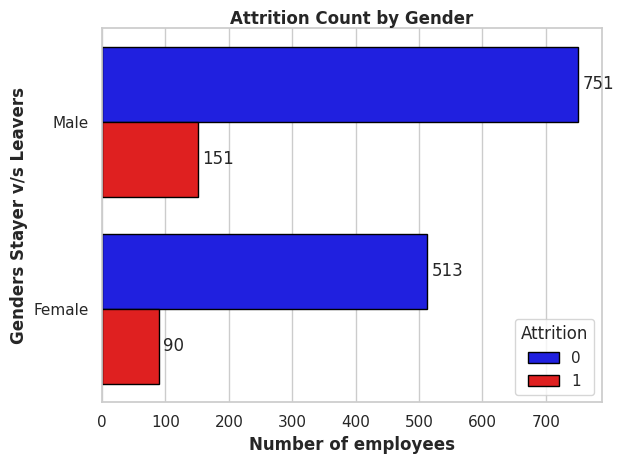

In [ ]:
sns.set_theme(style='whitegrid')
ax = sns.countplot(data=df, y='Gender', hue='Attrition', palette=['blue', 'red'], edgecolor='black')

for container in ax.containers:
  ax.bar_label(container, fmt='{:,.0f}', padding=3)
plt.title('Attrition Count by Gender', fontsize=12, fontweight='bold', pad=3)
plt.xlabel('Number of employees', fontweight='bold')
plt.ylabel('Genders Stayer:0 v/s Leavers:1', fontweight='bold')
plt.tight_layout()
plt.show()